### Fuzzification and Defuzzification for Temperature Control Decision System

This notebook demonstrates a fuzzy logic system for controlling fan speed based on temperature input.

In [1]:
!pip install scikit-fuzzy
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

#### Step 1: Define Input and Output Variables

In [2]:
temperature = ctrl.Antecedent(
    np.arange(0, 51, 1),
    'temperature'
)

fan_speed = ctrl.Consequent(
    np.arange(0, 101, 1),
    'fan_speed'
)

#### Step 2: Define Membership Functions

In [3]:
temperature['cold'] = fuzz.trimf(
    temperature.universe,
    [0, 0, 25]
)

temperature['warm'] = fuzz.trimf(
    temperature.universe,
    [15, 25, 35]
)

temperature['hot'] = fuzz.trimf(
    temperature.universe,
    [25, 50, 50]
)

fan_speed['low'] = fuzz.trimf(
    fan_speed.universe,
    [0, 0, 50]
)

fan_speed['medium'] = fuzz.trimf(
    fan_speed.universe,
    [25, 50, 75]
)

fan_speed['high'] = fuzz.trimf(
    fan_speed.universe,
    [50, 100, 100]
)

#### Step 3: Define Fuzzy Rules

In [4]:
rule1 = ctrl.Rule(
    temperature['cold'],
    fan_speed['low']
)

rule2 = ctrl.Rule(
    temperature['warm'],
    fan_speed['medium']
)

rule3 = ctrl.Rule(
    temperature['hot'],
    fan_speed['high']
)

#### Step 4: Create Control System

In [5]:
fan_control = ctrl.ControlSystem([
    rule1,
    rule2,
    rule3
])

fan_simulation = ctrl.ControlSystemSimulation(
    fan_control
)

#### Step 5: Enter Crisp Temperature

In [6]:
input_temperature = 30

fan_simulation.input[
    'temperature'
] = input_temperature

#### Step 6: Perform Fuzzy Inference

In [7]:
fan_simulation.compute()

#### Step 7: Display Output

In [8]:
output_speed = fan_simulation.output['fan_speed']

print("==============================================")
print("FUZZY TEMPERATURE CONTROL SYSTEM")
print("==============================================")
print("Input Temperature :", input_temperature, "°C")

print(
    "Recommended Fan Speed :",
    round(output_speed, 2),
    "%"
)

FUZZY TEMPERATURE CONTROL SYSTEM
Input Temperature : 30 °C
Recommended Fan Speed : 58.21 %


#### Step 8: Display Temperature Membership Values

In [9]:
cold_membership = fuzz.interp_membership(
    temperature.universe,
    temperature['cold'].mf,
    input_temperature
)

warm_membership = fuzz.interp_membership(
    temperature.universe,
    temperature['warm'].mf,
    input_temperature
)

hot_membership = fuzz.interp_membership(
    temperature.universe,
    temperature['hot'].mf,
    input_temperature
)

print("\nMembership Values")
print("----------------------------------------------")

print(
    "Cold :",
    round(cold_membership, 3)
)

print(
    "Warm :",
    round(warm_membership, 3)
)

print(
    "Hot :",
    round(hot_membership, 3)
)


Membership Values
----------------------------------------------
Cold : 0.0
Warm : 0.5
Hot : 0.2


#### Step 9: Interpret Decision

In [10]:
print("\nDecision")

if output_speed < 35:
    print("Fan Speed Level : LOW")

elif output_speed < 70:
    print("Fan Speed Level : MEDIUM")

else:
    print("Fan Speed Level : HIGH")


Decision
Fan Speed Level : MEDIUM


#### Step 10: Plot Membership Functions

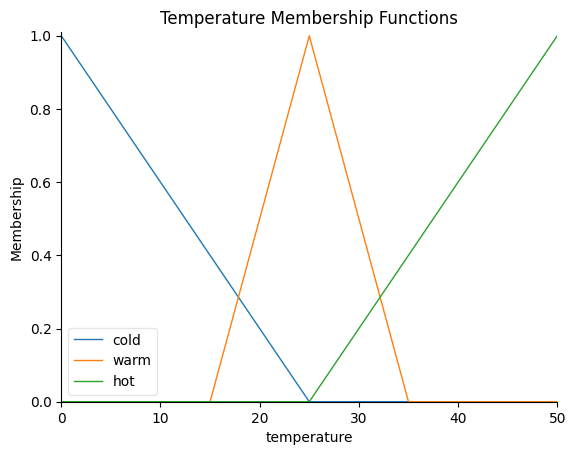

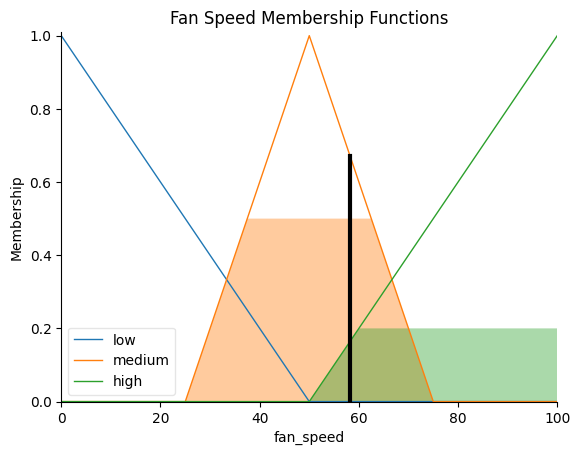

In [11]:
temperature.view()

plt.title(
    "Temperature Membership Functions"
)

plt.show()


fan_speed.view(
    sim=fan_simulation
)

plt.title(
    "Fan Speed Membership Functions"
)

plt.show()